# BERT z podziałem na fragmenty, BELT (spam w klasie negatywnej)

Wariant `spam_0`: wykrywamy tylko phishing, więc spam należy do klasy negatywnej (etykieta `label_spam_0`).

- **Model:** `bert-base-uncased` dostrajany w całości, z jednym wyjściem na tokenie `[CLS]`. Wiadomość jest dzielona na fragmenty
  po 510 tokenów treści funkcją `split_overlapping` z biblioteki belt-nlp (BELT, ang. *BERT For Longer Texts*), bez nakładania się
  fragmentów. Końcowy fragment krótszy niż 128 tokenów jest pomijany. Każdy fragment dostaje `[CLS]` i `[SEP]`, a wynik
  wiadomości to sigmoida ze średniego logitu fragmentów, jak w `BertClassifierWithPooling`. Uczenie przechodzi przez wszystkie
  fragmenty, więc gradient płynie przez cały tekst.
- **Różnica względem BERT 512:** tylko podział zamiast obcięcia. Pętla uczenia, tokeny maskowania, batch 16 wiadomości i ocena
  są takie same. Pętla `fit` z belt-nlp nie jest używana, bo nie ma rozgrzewki, harmonogramu, fp16 ani wczesnego zatrzymania.
- **Tokeny maskowania:** `[URL]`, `[EMAIL_ADDRESS]` i pozostałe są dodane do słownika jako niepodzielne tokeny. Ich początkowy wektor
  to średnia wektorów części, na które dzielił je oryginalny tokenizator.
- **Uczenie:** AdamW (zanik wag 0.01), rozgrzewka przez 10% kroków i liniowy spadek kroku uczenia, batch 16, fp16, przycinanie
  gradientu do normy 1. Batche są wyrównywane do najdłuższej wiadomości w batchu.
- **Dobór hiperparametrów:** krok uczenia jest przejęty z `bert_512_spam_0`. Liczba epok jest dobierana na tym samym foldzie
  holdout (fold 0 z `cluster_folds`) wczesnym zatrzymaniem na AUCPR ważonym, liczonym co pół epoki (najwyżej 4 epoki,
  cierpliwość 2 oceny).
- **Model końcowy:** uczony na całym zbiorze treningowym przez tyle epok, ile wynosiła najlepsza liczba epok na holdoucie.
- **Podział, próg i ocena:** jak w pozostałych eksperymentach (60/30/10 po klastrach, próg przy FPR ważonym 1% na val).

In [ ]:
import gc
import sys
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import average_precision_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import (
    ID_SOURCES, INK_SECONDARY, OOD_SOURCES, TARGET_FPR, cluster_folds, cluster_weights, corpus_metrics, load_corpora,
    plot_confusion_matrices, plot_curves, threshold_at_fpr,
)
from bert_utils import DEVICE, encode_chunks, load_tokenizer, predict, train_bert

EXPERIMENT = "bert_belt_spam_0"
LABEL = "label_spam_0"
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

MAX_LENGTH = 512
CHUNK_SIZE, STRIDE, MINIMAL_CHUNK_LENGTH = 510, 510, 128
MAX_CHUNKS = 16
BATCH_SIZE = 16
LEARNING_RATES = (float(pd.read_csv(ROOT / "results" / "bert_512_spam_0" / "tables" / "threshold.csv").learning_rate[0]),)
MAX_EPOCHS = 4
EVALS_PER_EPOCH = 2
PATIENCE = 2
N_FOLDS, HOLDOUT_FOLD = 3, 0
SEED = 42
REUSE_HOLDOUT = True
LR_COLORS = {2e-5: "#2a78d6", 3e-5: "#eb6834", 5e-5: "#1baf7a"}
print("Urządzenie:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

/home/ubuntu/phishing-thesis/venv312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Urządzenie: cuda NVIDIA GeForce RTX 2080


## Dane i podział

In [2]:
# Tylko kolumny potrzebne w eksperymencie: przy 16 GB RAM pełne ramki z treścią i tematem zajmują zbyt dużo pamięci.
COLUMNS = ["source", "kind", "label_spam_0", "label_spam_1", "cluster", "text"]
in_domain, out_of_domain = load_corpora()
in_domain = in_domain[COLUMNS + ["split", "raw_key"]].rename(columns={"raw_key": "id"})
out_of_domain = out_of_domain[COLUMNS + ["uid"]].rename(columns={"uid": "id"})
train, val, test = (in_domain[in_domain.split == name] for name in ("train", "val", "test"))
assert not set(train.cluster) & set(val.cluster) and not set(train.cluster) & set(test.cluster) and not set(val.cluster) & set(test.cluster)
print({name: len(frame) for name, frame in (("train", train), ("val", val), ("test", test), ("ood", out_of_domain))})

start = time.perf_counter()
tokenizer = load_tokenizer()
id_sequences, in_domain["n_tokens"] = encode_chunks(tokenizer, in_domain.text, CHUNK_SIZE, STRIDE, MINIMAL_CHUNK_LENGTH)
ood_sequences, out_of_domain["n_tokens"] = encode_chunks(tokenizer, out_of_domain.text, CHUNK_SIZE, STRIDE, MINIMAL_CHUNK_LENGTH)
in_domain["n_chunks"] = [len(chunks) for chunks in id_sequences]
out_of_domain["n_chunks"] = [len(chunks) for chunks in ood_sequences]
position = pd.Series(np.arange(len(in_domain)), index=in_domain.index)
in_domain, out_of_domain = in_domain.drop(columns="text"), out_of_domain.drop(columns="text")
train, val, test = (in_domain[in_domain.split == name] for name in ("train", "val", "test"))


def sequences(frame):
    return ood_sequences if frame is out_of_domain else [id_sequences[i] for i in position[frame.index]]


truncated = np.mean(in_domain.n_tokens > MAX_LENGTH) * 100
gc.collect()
print(f"Tokenizacja: {time.perf_counter() - start:.0f} s, wiadomości ID dłuższe niż {MAX_LENGTH} tokenów: {truncated:.1f}%")
print("Fragmentów na wiadomość:", in_domain.groupby("split").n_chunks.agg(["mean", "max"]).round(3).to_dict("index"),
      "OOD:", round(out_of_domain.n_chunks.mean(), 4))

{'train': 80679, 'val': 40720, 'test': 13070, 'ood': 6124}


Tokenizacja: 18 s, wiadomości ID dłuższe niż 512 tokenów: 16.0%
Fragmentów na wiadomość: {'test': {'mean': 1.321, 'max': 10}, 'train': {'mean': 1.22, 'max': 16}, 'val': {'mean': 1.177, 'max': 13}} OOD: 1.0


## Wybór liczby epok na holdoucie

Część uczącą i holdout wyznacza fold 0 z `cluster_folds`, tak samo jak w BERT 512. Model z krokiem uczenia przejętym z BERT 512
jest uczony przez najwyżej `MAX_EPOCHS` epok z harmonogramem rozpisanym na ten czas. Co pół epoki liczone jest AUCPR ważone
na holdoucie, a uczenie kończy się po `PATIENCE` ocenach bez poprawy.

In [3]:
fit_index, holdout_index = cluster_folds(train[LABEL], train.cluster, N_FOLDS, SEED)[HOLDOUT_FOLD]
fit_frame, holdout_frame = train.iloc[fit_index], train.iloc[holdout_index]
assert not set(fit_frame.cluster) & set(holdout_frame.cluster)
fit_sequences, holdout_sequences = sequences(fit_frame), sequences(holdout_frame)
holdout_labels, holdout_weights = holdout_frame[LABEL].to_numpy(), cluster_weights(holdout_frame.cluster)
steps_per_epoch = int(np.ceil(len(fit_frame) / BATCH_SIZE))
print(f"Część ucząca: {len(fit_frame)}, holdout: {len(holdout_frame)}, kroków na epokę: {steps_per_epoch}")

grid_rows, history_rows = [], []
grid_start = time.perf_counter()
reuse = REUSE_HOLDOUT and (TABLES / "holdout_results.csv").exists() and (TABLES / "holdout_history.csv").exists()
for learning_rate in () if reuse else LEARNING_RATES:
    start = time.perf_counter()
    print(f"krok uczenia {learning_rate}", flush=True)
    model, history, best_step = train_bert(
        tokenizer, fit_sequences, fit_frame[LABEL], learning_rate, SEED, MAX_EPOCHS * steps_per_epoch,
        batch_size=BATCH_SIZE, holdout=(holdout_sequences, holdout_labels, holdout_weights),
        eval_every=steps_per_epoch // EVALS_PER_EPOCH, patience=PATIENCE, max_chunks=MAX_CHUNKS, log=lambda text: print(text, flush=True),
    )
    scores = predict(model, tokenizer, holdout_sequences)
    grid_rows.append({
        "learning_rate": learning_rate, "best_step": best_step, "best_epoch": best_step / steps_per_epoch,
        "aucpr_ważone": average_precision_score(holdout_labels, scores, sample_weight=holdout_weights),
        "aucpr": average_precision_score(holdout_labels, scores), "czas_s": time.perf_counter() - start,
    })
    history_rows += [{"learning_rate": learning_rate, "krok": step, "epoka": step / steps_per_epoch, "aucpr_ważone": score} for step, score in history]
    del model
    gc.collect()
    torch.cuda.empty_cache()
grid_seconds = time.perf_counter() - grid_start

if reuse:
    print("Wczytano zapisane wyniki wyboru kroku uczenia.")
    holdout_results, holdout_history = pd.read_csv(TABLES / "holdout_results.csv"), pd.read_csv(TABLES / "holdout_history.csv")
    grid_seconds = holdout_results.czas_s.sum()
else:
    holdout_results = pd.DataFrame(grid_rows).sort_values("aucpr_ważone", ascending=False).reset_index(drop=True)
    holdout_results.to_csv(TABLES / "holdout_results.csv", index=False)
    holdout_history = pd.DataFrame(history_rows)
    holdout_history.to_csv(TABLES / "holdout_history.csv", index=False)
best = holdout_results.iloc[0]
print(f"Czas wyboru kroku uczenia: {grid_seconds / 60:.1f} min")
display(holdout_results)

Część ucząca: 53787, holdout: 26892, kroków na epokę: 3362
krok uczenia 3e-05



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11087.64it/s]

  krok 1681/13448: AUCPR ważone 0.9159


  krok 3362/13448: AUCPR ważone 0.9336


  krok 5043/13448: AUCPR ważone 0.9408


... (2 outputs left out)

  krok 10086/13448: AUCPR ważone 0.9399


  krok 11767/13448: AUCPR ważone 0.9224


Czas wyboru kroku uczenia: 42.7 min


,learning_rate,best_step,best_epoch,aucpr_ważone,aucpr,czas_s
0,0.0000,8405,2.5000,0.9417,0.9342,2559.5159


Przebieg AUCPR ważonego na holdoucie w trakcie uczenia.

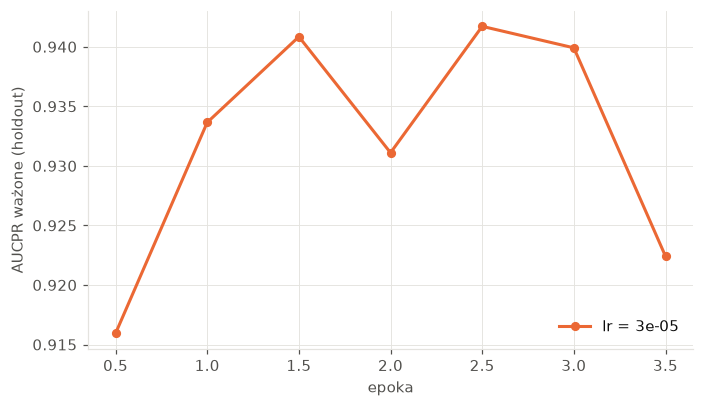

In [4]:
figure, axis = plt.subplots(figsize=(6.5, 3.8))
for learning_rate, color in LR_COLORS.items():
    if learning_rate not in set(holdout_history.learning_rate):
        continue
    curve = holdout_history[holdout_history.learning_rate == learning_rate]
    axis.plot(curve.epoka, curve.aucpr_ważone, color=color, linewidth=2, marker="o", markersize=5, label=f"lr = {learning_rate:g}")
axis.set_xlabel("epoka")
axis.set_ylabel("AUCPR ważone (holdout)")
axis.legend(loc="lower right")
figure.tight_layout()
figure.savefig(FIGURES / "holdout_aucpr.pdf")
plt.show()

## Uczenie modelu końcowego

Model z najlepszym krokiem uczenia jest uczony na całym zbiorze treningowym przez najlepszą liczbę epok z holdoutu, z harmonogramem
rozpisanym na tę liczbę kroków.

In [5]:
best_params = {"learning_rate": float(best.learning_rate), "n_epochs": float(best.best_epoch)}
final_steps = max(1, int(round(best.best_epoch * np.ceil(len(train) / BATCH_SIZE))))
start = time.perf_counter()
model, _, _ = train_bert(
    tokenizer, sequences(train), train[LABEL], best_params["learning_rate"], SEED, final_steps, batch_size=BATCH_SIZE,
    max_chunks=MAX_CHUNKS,
)
training_seconds = time.perf_counter() - start
print(best_params, f"kroków: {final_steps}, czas uczenia: {training_seconds / 60:.1f} min")


def score(frame):
    return predict(model, tokenizer, sequences(frame))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10734.43it/s]

{'learning_rate': 3e-05, 'n_epochs': 2.5} kroków: 12608, czas uczenia: 37.2 min


## Dobór progu na zbiorze walidacyjnym

In [6]:
threshold_result = threshold_at_fpr(val[LABEL], score(val), val.cluster)
threshold = threshold_result["próg"]
threshold_table = pd.DataFrame([{
    "docelowy_fpr": TARGET_FPR, **threshold_result, **best_params, "kroki": final_steps,
    "aucpr_ważone_holdout": best["aucpr_ważone"], "czas_wyboru_lr_s": grid_seconds, "czas_uczenia_s": training_seconds,
}])
threshold_table.to_csv(TABLES / "threshold.csv", index=False)
display(threshold_table)

,docelowy_fpr,próg,fpr_ważony_val,fpr_val,recall_val,learning_rate,n_epochs,kroki,aucpr_ważone_holdout,czas_wyboru_lr_s,czas_uczenia_s
0,0.0100,0.7656,0.0100,0.0188,0.9520,0.0000,2.5000,12608,0.9417,2559.8446,2232.2759


## Metryki dla ID i OOD

In [7]:
test_scores, ood_scores = score(test), score(out_of_domain)
corpus_sets = {"ID": (test[LABEL], test_scores), "OOD": (out_of_domain[LABEL], ood_scores)}
metrics = corpus_metrics(corpus_sets, threshold)
metrics.to_csv(TABLES / "metrics.csv", index_label="korpus")
display(metrics)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
ID,13070.0000,1253.0000,0.9800,0.9218,0.8985,0.8763,0.9893,0.9345,0.0138
OOD,6124.0000,4987.0000,0.5145,0.4957,0.6245,0.8437,0.5706,0.8634,0.4028


## Metryki według źródła

Puste wartości oznaczają metrykę, której nie da się policzyć dla jednej klasy, np. FPR dla Nazario, które ma tylko phishing.

In [8]:
source_sets = {
    name: (test.loc[test.source == name, LABEL], test_scores[(test.source == name).to_numpy()]) for name in ID_SOURCES
} | {
    name: (out_of_domain.loc[out_of_domain.source == name, LABEL], ood_scores[(out_of_domain.source == name).to_numpy()])
    for name in OOD_SOURCES
}
metrics_by_source = corpus_metrics(source_sets, threshold)
metrics_by_source.to_csv(TABLES / "metrics_by_source.csv", index_label="source")
display(metrics_by_source)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
nazario,918.0000,918.0000,0.9608,0.9608,0.9800,1.0000,NaN,NaN,NaN
nigerian,335.0000,335.0000,0.8149,0.8149,0.8980,1.0000,NaN,NaN,NaN
trec05,5386.0000,0.0000,0.9792,NaN,0.0000,0.0000,NaN,NaN,0.0208
trec06,1582.0000,0.0000,0.9842,NaN,0.0000,0.0000,NaN,NaN,0.0158
trec07,4849.0000,0.0000,0.9946,NaN,0.0000,0.0000,NaN,NaN,0.0054
ferb,5601.0000,4707.0000,0.4962,0.4827,0.6169,0.8545,0.5389,0.8796,0.4329
kd10000,60.0000,55.0000,0.7333,0.7091,0.8298,1.0000,0.9655,0.9967,0.0000
nebulon,145.0000,69.0000,0.6966,0.5507,0.6333,0.7451,0.7430,0.7158,0.1711
zeroday,318.0000,156.0000,0.7138,0.7885,0.7300,0.6796,0.8159,0.7978,0.3580


## Macierze pomyłek i krzywe

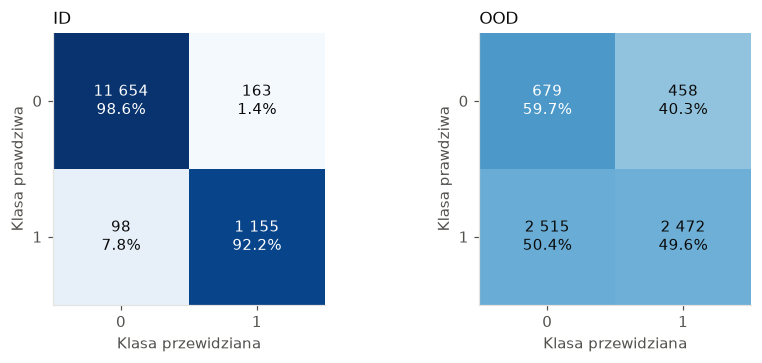

,przewidziane 0,przewidziane 1
prawdziwe 0,11654,163
prawdziwe 1,98,1155


,przewidziane 0,przewidziane 1
prawdziwe 0,679,458
prawdziwe 1,2515,2472


In [9]:
matrices = plot_confusion_matrices(corpus_sets, threshold, FIGURES / "confusion_matrices.pdf")
for name, matrix in matrices.items():
    matrix.to_csv(TABLES / f"confusion_matrix_{name.lower()}.csv")
    display(matrix)

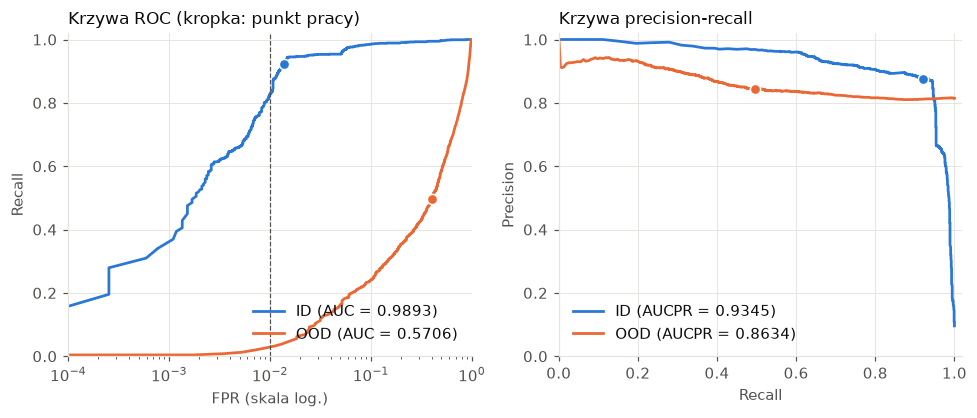

In [10]:
plot_curves(corpus_sets, threshold, FIGURES / "roc_pr_curves.pdf")

## Predykcje na teście

Wynik modelu dla każdej wiadomości testowej ID i OOD, z liczbą tokenów i fragmentów. `truncated` oznacza wiadomość, którą
BERT 512 by obciął. Służą do analizy błędów
(`bert_512_error_analysis.ipynb`). `id` to `raw_key` dla ID i `uid` dla OOD.

In [11]:
predictions = pd.concat([
    frame[["id", "source", "kind", "cluster", "n_tokens", "n_chunks"]].assign(korpus=name, label=frame[LABEL].to_numpy(), score=scores)
    for name, frame, scores in (("ID", test, test_scores), ("OOD", out_of_domain, ood_scores))
], ignore_index=True)
predictions["pred"] = (predictions.score >= threshold).astype(int)
predictions["truncated"] = predictions.n_tokens > MAX_LENGTH
predictions.to_csv(TABLES / "predictions.csv", index=False)
print(predictions.groupby("korpus").truncated.mean())

korpus
ID    0.2015
OOD   0.0002
Name: truncated, dtype: float64
